# Задача 1

## 1. Данные

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

events = pd.read_excel('data/NHL-playoffs-2026.xlsx', index_col=0)
events.shape

(29710, 38)

In [2]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


в таблице 29710 событий и 38 признаков, каждое наблюдение соответствует отдельному событию во время матча: броску, голу, вбрасыванию, силовому приёму и так далее

данные охватывают 82 матча с участием 16 команд с 18 апреля по 14 июня 2026 года, по первым строкам видно, как начало периода и вбрасывание сменяются игровыми действиями

## 2. Информация о матчах

In [3]:
games = events[events['Play Type'] == 'game-end'].set_index('Game ID')
games = games[['Date', 'Away Team', 'Home Team',
               'Cumulated Away Score', 'Cumulated Home Score', 'Period']].copy()
games = games.rename(columns={'Cumulated Away Score': 'Away Score',
                              'Cumulated Home Score': 'Home Score'})
games['Outcome'] = games.pop('Period').map({3: 'Final', 4: 'Final/OT', 5: 'Final/2OT'})
games.tail()

,Date,Away Team,Home Team,Away Score,Home Score,Outcome
Game ID,,,,,,
2025030412,2026-06-04,Vegas Golden Knights,Carolina Hurricanes,3,4,Final/OT
2025030413,2026-06-06,Carolina Hurricanes,Vegas Golden Knights,4,5,Final/2OT
2025030414,2026-06-09,Carolina Hurricanes,Vegas Golden Knights,5,3,Final
2025030415,2026-06-11,Vegas Golden Knights,Carolina Hurricanes,2,4,Final
2025030416,2026-06-14,Carolina Hurricanes,Vegas Golden Knights,3,0,Final


получилась таблица из 82 строк, по одной на матч, с датой, командами, итоговым счётом и способом завершения игры

60 матчей закончились в основное время, 18 потребовали одного овертайма и ещё 4 закончились во втором овертайме, то есть примерно в 27% матчей трёх периодов оказалось недостаточно

## 3. Функция gameInfo

In [4]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return (f"{g['Home Team']} - {g['Away Team']} "
            f"({g['Home Score']} - {g['Away Score']}, {g['Outcome']}, {g['Date']})")

gameInfo(games.index.min())

'Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)'

In [5]:
gameInfo(games.index.max())

'Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)'

функция возвращает названия команд, счёт, способ завершения и дату матча, хозяева всегда стоят первыми, поэтому и счёт читается в порядке хозяева - гости

например, Buffalo Sabres выиграли у Boston Bruins 4:3 в основное время 19 апреля, а в матче с последним идентификатором Vegas Golden Knights проиграли Carolina Hurricanes 0:3

## 4. Число голов

In [6]:
games['Total Score'] = games['Away Score'] + games['Home Score']
games['Total Score'].describe().round(3)

count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64

за 82 матча команды забили 486 голов, в среднем получилось 5.93 гола за игру, медиана равна 6, поэтому типичный матч по результативности находится примерно на этом уровне

первый и третий квартили равны 5 и 7, стандартное отклонение составляет около 2.26 гола, при этом крайние значения различаются сильно: от одного гола до 15

## 5. Распределение числа голов

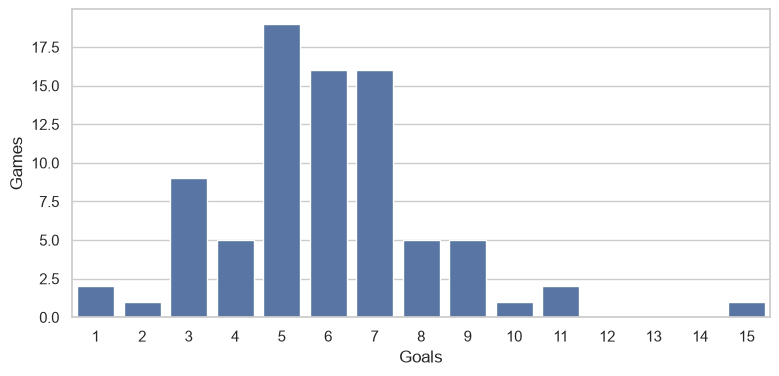

In [7]:
plt.figure(figsize=(9, 4))
sns.countplot(data=games, x='Total Score', order=range(1, games['Total Score'].max() + 1))
plt.xlabel('Goals')
plt.ylabel('Games')
plt.show()

самый частый результат по суммарному числу голов равен 5, таких матчей было 19, по 6 и 7 голов забивали в 16 матчах, вместе это 51 матч из 82, или примерно 62% всех игр

матчи с очень высокой результативностью встречаются гораздо реже, 10 и более голов было только в 4 играх, причём один матч с 15 голами заметно отделяется от остальных

основная часть распределения сосредоточена около 5-7 голов, а длинный правый хвост связан с несколькими особенно результативными играми

## 6. Самые результативные и нерезультативные матчи

In [8]:
[gameInfo(i) for i in games.index[games['Total Score'] == games['Total Score'].min()]]

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)',
 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

In [9]:
[gameInfo(i) for i in games.index[games['Total Score'] == games['Total Score'].max()]]

['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

минимум составил один гол, таких матчей два: Montréal Canadiens проиграли Tampa Bay Lightning 0:1, а Philadelphia Flyers обыграли Pittsburgh Penguins 1:0

обе игры закончились в овертайме, значит, за три основных периода команды не забили ни одной шайбы и единственный гол сразу определил победителя

максимум составил 15 голов в матче Colorado Avalanche против Minnesota Wild 3 мая, Colorado выиграли 9:6, высокая общая результативность здесь складывается из большого числа голов обеих команд

## 7. Число игроков

In [10]:
player_cols = [c for c in events.columns if 'Player on the Ice' in c or 'Goalie' in c]
players = events.melt(id_vars='Game ID', value_vars=player_cols, value_name='Player')
players = players[['Game ID', 'Player']].dropna().drop_duplicates()
player_count = players.groupby('Game ID').size()

most_players = player_count[player_count == player_count.max()].to_frame('Player Count')
most_players.insert(0, 'Game Info', most_players.index.map(gameInfo))
most_players

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


больше всего игроков участвовало в матче Montréal Canadiens против Buffalo Sabres 16 мая, который закончился со счётом 3:8, в составе обеих команд суммарно получилось 40 разных игроков

каждый игрок учитывается один раз за матч, независимо от числа событий с его участием и позиции в столбцах состава, вратари тоже входят в этот подсчёт

в примере задания указано 41, такое число получается, если включить пропуск в список уникальных значений, после удаления пропусков остаётся 40 игроков

## 8. Расстояние до ворот

In [11]:
shots = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])].copy()
x = 'X Coordinate on the Ice Rink'
y = 'Y Coordinate on the Ice Rink'
home = shots['Team Making the Play'] == shots['Home Team']
left = shots["Home Team's Defending Side"] == 'left'
goal_x = np.where(home == left, 89, -89)

shots['Shot Length'] = np.hypot(shots[x] - goal_x, np.maximum(shots[y].abs() - 3, 0))
events.loc[shots.index, 'Shot Length'] = shots['Shot Length']
shots[['Game ID', 'Play Type', 'Shot Length']].round(3)

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


расстояние посчитано для 7266 незаблокированных бросков: 4623 попали в створ, включая голы, а 2643 прошли мимо

ворота рассматриваются как отрезок шириной 6 футов, если координата y броска находится между -3 и 3, ближайшая точка ворот лежит прямо напротив броска и достаточно расстояния по горизонтали, в остальных случаях ближайшей точкой будет одна из штанг

сторона ворот выбирается с учётом команды, которая бросает, и стороны защиты хозяев, поэтому расстояние измеряется до ворот соперника, все значения остаются в футах

## 9. Длина точных и неточных бросков

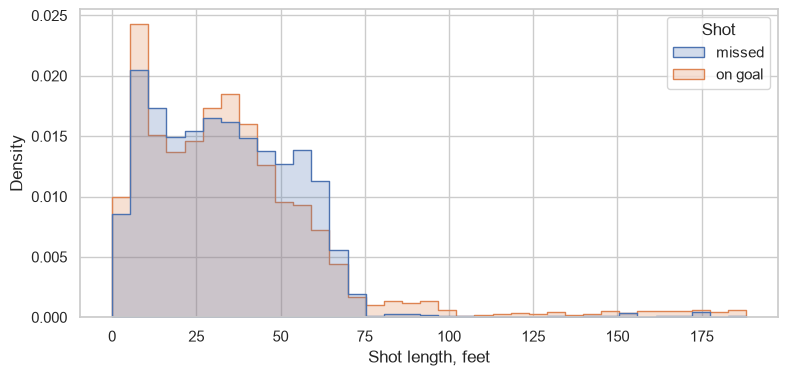

In [12]:
shots['Shot'] = np.where(shots['Play Type'] == 'missed-shot', 'missed', 'on goal')

plt.figure(figsize=(9, 4))
sns.histplot(data=shots, x='Shot Length', hue='Shot', bins=35,
             stat='density', common_norm=False, element='step')
plt.xlabel('Shot length, feet')
plt.ylabel('Density')
plt.show()

In [13]:
shots.groupby('Shot')['Shot Length'].agg(['mean', 'median']).round(3)

,mean,median
Shot,,
missed,34.014,32.249
on goal,36.207,31.828


для каждой группы гистограмма нормирована отдельно, площадь под ней равна 1, поэтому можно сравнить форму распределений при разном числе точных и неточных бросков

распределения довольно похожи, медиана длины точного броска равна 31.83 фута, неточного 32.25 фута, то есть примерно половина бросков в каждой группе выполняется с расстояния до 32 футов

при этом средняя длина точного броска выше: 36.21 против 34.01 фута, это согласуется с более заметным длинным хвостом точных бросков

вероятно, часть дальних точных бросков возникает при выбросах шайбы со своей половины, когда она доходит до вратаря, ещё одна возможная причина связана с попытками попасть в пустые ворота, попадание в створ с такого расстояния не обязательно означает опасный момент

## 10. Доля точных бросков в каждом матче

In [14]:
numshots = shots.groupby(['Game ID', 'Team Making the Play', 'Play Type']).size().unstack(fill_value=0)
numshots['Shot'] = numshots['shot-on-goal'] + numshots['goal']
numshots['Goal'] = numshots['goal']
numshots['Share of Shots on Goal'] = numshots['Shot'] / (numshots['Shot'] + numshots['missed-shot'])
numshots['Share of Shots on Goal'].round(3)

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

In [15]:
numshots['Share of Shots on Goal'].describe().round(3)

count    164.000
mean       0.639
std        0.085
min        0.353
25%        0.583
50%        0.639
75%        0.689
max        0.860
Name: Share of Shots on Goal, dtype: float64

получено 164 значения, по одному для каждой команды в каждом из 82 матчей, в числителе стоят броски в створ вместе с голами, в знаменателе к ним добавлены броски мимо, заблокированные броски сюда не входят

средняя доля равна 63.9%, медиана почти такая же, 63.9%, то есть в типичном случае в створ попадает немного меньше двух третей незаблокированных бросков

первый и третий квартили составляют 58.3% и 68.9%, при этом минимум равен 35.3%, а максимум 86.0%, в отдельных матчах точность заметно отличается от обычного уровня

## 11. Самые точные и неточные команды

In [16]:
avgnumshots = numshots.groupby('Team Making the Play')['Share of Shots on Goal'].mean()
avgnumshots.nlargest(5).round(3)

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

In [17]:
avgnumshots.nsmallest(5).round(3)

Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64

среди лидеров Edmonton Oilers с 70.6%, Philadelphia Flyers с 68.4% и Dallas Stars с 67.0%, далее идут Minnesota Wild и Colorado Avalanche с результатами около 65%

самая низкая средняя доля у Pittsburgh Penguins, 55.4%, затем идут Utah Mammoth с 59.9% и Carolina Hurricanes с 61.5%, Tampa Bay Lightning и Buffalo Sabres имеют близкие значения около 62.6%

разница между первой и последней командой составляет около 15.2 процентного пункта, здесь усредняются доли за отдельные матчи, поэтому каждая игра команды имеет одинаковый вес

этот показатель описывает попадание в створ, но сам по себе не показывает результативность, например, Carolina Hurricanes находятся в нижней пятёрке по точности, хотя забивают в среднем около 3.47 гола за матч

## 12. Броски и голы за матч

In [18]:
avgshots = numshots.groupby('Team Making the Play')[['Shot', 'Goal']].mean()
avgshots.round(3)

Play Type,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


больше всего бросков в створ за матч у Colorado Avalanche, в среднем 32.15, рядом находятся Anaheim Ducks с 31.67 и Carolina Hurricanes с 31.63, меньше всего у Montréal Canadiens, 23.26

по голам лидируют Minnesota Wild с 3.73 за матч, затем идут Edmonton Oilers с 3.50 и Carolina Hurricanes с 3.47, самые низкие значения у Los Angeles Kings и Ottawa Senators, по 1.25 гола

лидеры по броскам и голам не полностью совпадают, например, Dallas Stars наносят 31 бросок за матч и забивают 2.50 гола, а Edmonton Oilers при 28.33 броска забивают 3.50, значит, различия в числе бросков объясняют только часть различий в результативности

## 13. Связь между бросками и голами

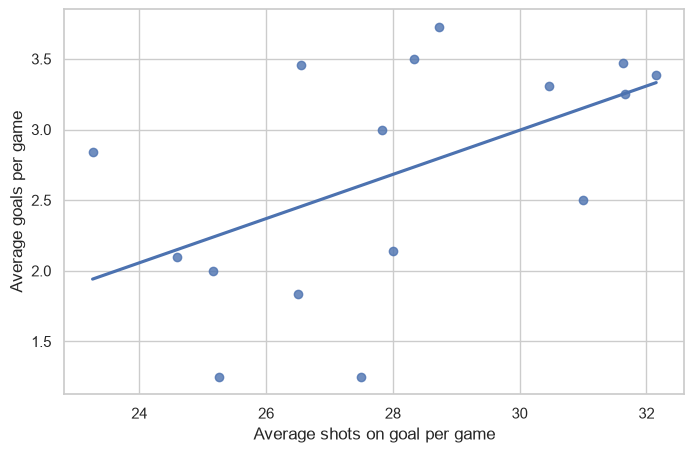

In [19]:
plt.figure(figsize=(8, 5))
sns.regplot(data=avgshots, x='Shot', y='Goal', ci=None)
plt.xlabel('Average shots on goal per game')
plt.ylabel('Average goals per game')
plt.show()

In [20]:
avgshots['Shot'].corr(avgshots['Goal']).round(3)

np.float64(0.521)

линия регрессии направлена вверх, команды с большим средним числом бросков в створ в целом забивают больше, корреляция равна примерно 0.52, что указывает на умеренную положительную связь

при этом точки заметно разбросаны вокруг линии, например, Minnesota Wild при 28.73 броска забивают 3.73 гола за матч, а Dallas Stars при 31 броске забивают 2.50

на диаграмме всего 16 наблюдений, по одному среднему значению на команду, поэтому вывод относится к сравнению команд за этот плей-офф, по нему нельзя напрямую судить о связи бросков и голов внутри отдельного матча

## 14. Матч с наибольшим числом бросков

In [21]:
allshots = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot'])]
shot_count = allshots.groupby('Game ID').size()
idxmax = shot_count.idxmax()
print(gameInfo(idxmax))
shot_count.loc[idxmax]

Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)


np.int64(208)

максимум составил 208 бросков в матче Carolina Hurricanes против Ottawa Senators 20 апреля, Carolina выиграли 3:2 во втором овертайме

Carolina выполнили 109 бросков, Ottawa 99, всего в матче было 88 бросков в створ с учётом 5 голов, ещё 66 бросков прошли мимо и 54 были заблокированы

здесь сравнивается общее число бросков за игру, поэтому два овертайма дают больше времени для накопления бросков, такой максимум сам по себе не означает наибольшую интенсивность бросков в минуту

## 15. Броски на площадке

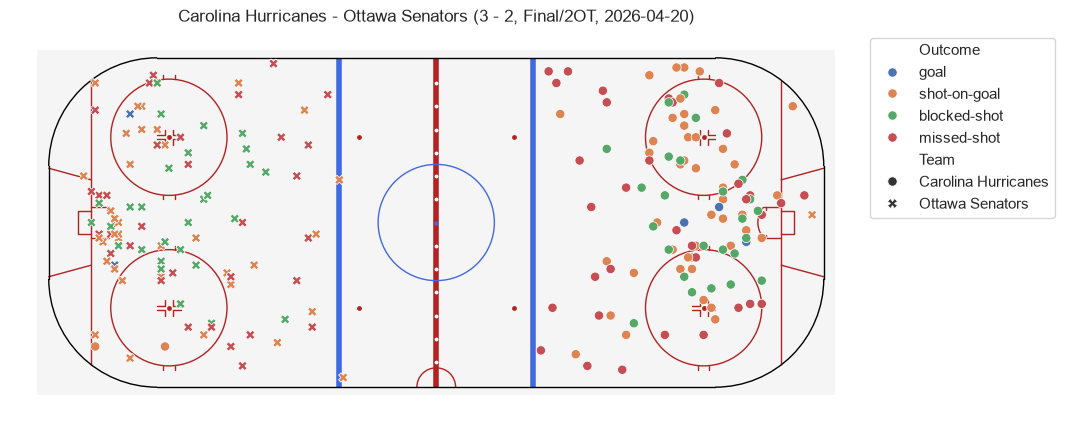

In [22]:
from rink import plot_rink

game_shots = allshots[allshots['Game ID'] == idxmax].copy()
odd = game_shots['Period'] % 2 == 1
game_shots.loc[odd, [x, y]] *= -1
game_shots = game_shots.rename(columns={'Play Type': 'Outcome', 'Team Making the Play': 'Team'})

plt.figure(figsize=(11, 5))
plot_rink()
sns.scatterplot(data=game_shots, x=x, y=y, hue='Outcome', style='Team',
                hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'], s=45)
plt.axis('equal')
plt.axis('off')
plt.legend(bbox_to_anchor=(1, 1))
plt.title(gameInfo(idxmax))
plt.show()

после преобразования координат Carolina Hurricanes атакуют правые ворота, Ottawa Senators левые, цвет точки показывает исход броска, а форма маркера команду

большинство бросков сосредоточено на половине соперника, но расстояния до ворот сильно различаются, видны броски как из зоны рядом с воротами, так и из более дальних точек, в том числе отдельные попытки со своей половины

цвета во многих участках смешиваются, из близких позиций бывают и точные броски, и промахи, и блокировки, по одной позиции броска нельзя однозначно определить его исход

## 16. Больше всего голов

In [23]:
goals = events[events['Play Type'] == 'goal']
player_goals = goals['Player in the Event #1'].value_counts()
player_goals.nlargest(10).to_frame('Goals')

,Goals
Player in the Event #1,
Brett Howden,14
Pavel Dorofeyev,12
Logan Stankoven,11
Mitch Marner,10
Nikolaj Ehlers,8
Jordan Staal,8
Alex Newhook,7
Taylor Hall,7
Jackson Blake,7


лидер по голам Brett Howden с 14 шайбами, далее идут Pavel Dorofeyev с 12, Logan Stankoven с 11 и Mitch Marner с 10

у остальных игроков в показанной десятке от 7 до 8 голов, это рейтинг по общему числу шайб за весь плей-офф, поэтому на него влияет и число сыгранных матчей

## 17. Больше всего передач

In [24]:
assists = goals[['Player in the Event #2', 'Player in the Event #3']].melt()['value'].value_counts()
assists.nlargest(10).to_frame('Assists')

,Assists
value,
Jack Eichel,20
Mitch Marner,19
Lane Hutson,13
Jackson Blake,13
Nick Suzuki,12
Taylor Hall,12
Martin Necas,12
Shea Theodore,12
Kirill Kaprizov,11


больше всего голевых передач у Jack Eichel, 20, всего на одну передачу отстаёт Mitch Marner с 19, у следующих в списке Lane Hutson и Jackson Blake по 13

учитываются оба поля с авторами передач, поэтому один гол может добавить по одной передаче двум разным игрокам, пустые значения не учитываются

у первых двух игроков заметный отрыв от остальных, при этом Mitch Marner входит и в четвёрку лучших по голам, то есть набирает много очков обоими способами

## 18. Гол плюс пас

In [25]:
points = player_goals.add(assists, fill_value=0).astype(int)
points.nlargest(10).to_frame('Points')

,Points
Player in the Event #1,
Mitch Marner,29
Jack Eichel,22
Jackson Blake,20
Taylor Hall,19
Brett Howden,18
Nikolaj Ehlers,18
Shea Theodore,18
Lane Hutson,16
Logan Stankoven,16


по сумме голов и передач первым становится Mitch Marner с 29 очками, у него 10 голов и 19 передач, Jack Eichel набрал 22 очка из 2 голов и 20 передач, Jackson Blake 20 очков из 7 голов и 13 передач

лидер по голам Brett Howden имеет 18 очков, к 14 голам у него добавляются 4 передачи, поэтому первое место по голам не совпадает с первым местом по общему числу очков

рейтинг показывает суммарный вклад в результативные атаки через завершение и передачи, при этом гол и каждая голевая передача дают по одному очку

## 19. Броски в створ за матч

In [26]:
played = players['Player'].value_counts()
on_goal = shots[shots['Play Type'].isin(['shot-on-goal', 'goal'])]
player_shots = on_goal['Player in the Event #1'].value_counts()
(player_shots / played).nlargest(10).round(3).to_frame('Shots per game')

,Shots per game
Player in the Event #1,
Jason Robertson,5.000
Dylan Guenther,4.500
Nikita Kucherov,4.429
Matt Boldy,4.364
Quinton Byfield,4.250
Darren Raddysh,4.000
Joel Eriksson Ek,4.000
Alex Laferriere,3.750
David Pastrnak,3.667


Jason Robertson лидирует с 5 бросками в створ за матч, это 30 бросков за 6 игр, у Dylan Guenther 4.50, у Nikita Kucherov около 4.43

в число точных бросков включены и голы, а в знаменателе стоят все матчи, в которых игрок выходил на лёд, в том числе игры без единого броска в створ

такой рейтинг сравнивает частоту бросков за матч и не даёт прямого преимущества игрокам только за более длинный плей-офф, при этом он не учитывает различия в игровом времени внутри матча

## 20. Силовые приёмы за матч

In [27]:
hits = events.loc[events['Play Type'] == 'hit', 'Player in the Event #1'].value_counts()
(hits / played).nlargest(10).round(3).to_frame('Hits per game')

,Hits per game
Player in the Event #1,
Lawson Crouse,6.333
Alex Turcotte,6.000
Alexander Petrovic,6.000
Yakov Trenin,5.667
Dylan Cozens,5.500
Vasily Podkolzin,5.333
Carl Grundstrom,5.000
Ivan Barbashev,5.000
Marcus Foligno,5.000


Lawson Crouse провёл 38 силовых приёмов за 6 матчей, в среднем около 6.33 за игру, следующие значения у Alex Turcotte и Alexander Petrovic, по 6

у двух последних игроков в данных только по одному матчу, поэтому их высокое среднее основано на гораздо меньшем числе наблюдений, чем у Crouse

силовой приём засчитывается игроку, который его выполнил, число приёмов делится на все его сыгранные матчи, как и в предыдущем пункте, это показатель за игру, без поправки на время на льду

## 21. Вратари без пропущенных голов

у 22 победных голов в овертайме не заполнен состав обеих команд, для этих событий беру вратаря из предыдущей записи того же матча, предполагая, что он оставался в воротах

остальные пропуски в поле вратаря не заполняю, чтобы голы в пустые ворота не засчитывались заменённому вратарю

In [28]:
goalie_cols = ["Away Team's Goalie", "Home Team's Goalie"]
goalies = events[goalie_cols].copy()
empty = ((events['Play Type'] == 'goal') &
         (events["# of Away Team's Players on the Ice"] == 0) &
         (events["# of Home Team's Players on the Ice"] == 0))
goalies.loc[empty] = goalies.groupby(events['Game ID']).shift().loc[empty]

goalie_games = goalies.assign(Game=events['Game ID']).melt(id_vars='Game', value_name='Goalie')
goalie_games = goalie_games[['Game', 'Goalie']].dropna().drop_duplicates()

conceded = goals[['Game ID']].rename(columns={'Game ID': 'Game'})
conceded['Goalie'] = np.where(goals['Team Making the Play'] == goals['Home Team'],
                             goalies.loc[goals.index, goalie_cols[0]],
                             goalies.loc[goals.index, goalie_cols[1]])
conceded = conceded.groupby(['Game', 'Goalie']).size().rename('Goals')
goalie_games = goalie_games.join(conceded, on=['Game', 'Goalie'])
goalie_games['Goals'] = goalie_games['Goals'].fillna(0)
goalie_games.loc[goalie_games['Goals'] == 0, 'Goalie'].value_counts().to_frame('Games without goals conceded')

,Games without goals conceded
Goalie,
Frederik Andersen,3
Dan Vladar,2
Andrei Vasilevskiy,1
Brandon Bussi,1
Joonas Korpisalo,1
Scott Wedgewood,1


получилось 6 вратарей, Frederik Andersen не пропустил ни одной шайбы за своё время на льду в 3 матчах, Dan Vladar в 2, Andrei Vasilevskiy, Brandon Bussi, Joonas Korpisalo и Scott Wedgewood по одному разу

здесь достаточно не пропустить за ту часть матча, которую сыграл конкретный вратарь, команда при этом могла пропускать до его выхода или после замены, поэтому этот список включает и неполные матчи без пропущенных голов

## 22. Чаще ли побеждает команда, которая больше бросает в створ?

In [29]:
results = numshots[['Shot', 'Goal']].copy()
results['Win'] = results['Goal'] == results.groupby('Game ID')['Goal'].transform('max')
leaders = results[results['Shot'] > results.groupby('Game ID')['Shot'].transform('mean')]
leaders['Win'].value_counts().rename(index={True: 'Win', False: 'Loss'}).to_frame('Games')

,Games
Win,
Win,47
Loss,31


In [30]:
leaders['Win'].mean().round(3)

np.float64(0.603)

в 4 матчах команды нанесли одинаковое число бросков в створ, у них нет лидера по этому показателю, поэтому в сравнении остаются 78 игр

в 47 из них победила команда с большим числом бросков, в 31 она проиграла, доля побед составила 60.3%, то есть преимущество по броскам чаще сопровождалось победой

при этом почти в 40% таких матчей выиграла команда, которая бросала меньше, число попаданий в створ не описывает качество моментов и то, какая их доля закончилась голами

ответ на вопрос положительный для этой выборки, но преимущество по числу бросков не гарантирует победу